# Original fake_spectra vs HCD fork: one skewer, timing and flux

One random sightline through a random TNG50-2 halo, extracted with:

| Config | Build | `filter_mode` |
|---|---|---|
| `upstream` | original v2.2.4 | (none) |
| `upstream_sf0` | original v2.2.4, `sf_neutral=False` | (none) |
| `fork_full` | fork | `"None"` |
| `fork_HCD` | fork | `"HCD_only"` |
| `fork_Forest` | fork | `"Forest_only"` |

Both builds are called `fake_spectra`, so each extraction runs in its own
subprocess (`extract_skewers.py`). The original build lives in
`benchmarks/fake_spectra_upstream/` (create it with `bash build_upstream.sh`).

**Expected:**
1. **colden** of `fork_full` and `upstream` is identical: both use `sf_neutral=True`
   (star-forming gas self-shielded, the right physics for TNG). `upstream_sf0` shows
   how much HI that correction adds.
2. **tau = 7/8 bug.** For the tophat kernel (TNG) the original under-estimates
   tau by about 7/8 (fixed in the fork's `singleabs.h`). colden is not affected.

In [ ]:
import os
import sys
import json
import subprocess
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib widget
%load_ext autoreload
%autoreload 2

# Same plotting style as the other notebooks (smaller fonts, smaller figures here)
plt.rc('font', family='serif', size=12)
plt.rcParams.update({
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.5,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# ==============================================================================
# CELL 1: CONFIGURATION
# ==============================================================================
# Project root = the folder that contains tools/
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())
BENCH_DIR = PROJ_ROOT / "benchmarks"

# --- simulation ---------------------------------------------------------------
SIM_NAME  = "TNG50-4"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"
SNAP_NUM  = 25                      # z ~ 3.01

# --- random skewer --------------------------------------------------------------
SEED          = 42                  # change it to get another halo/axis
LOG_MASS_MIN  = 11.5                # halo mass window, log10(M200 / Msun)
LOG_MASS_MAX  = 12.5
RES_KMS       = 10.0                # pixel width, as in the production runs
RADIUS_CUT    = 10.0                # HCD window, in R200 (as in tools/utils.py)

# --- the two builds -------------------------------------------------------------
UPSTREAM_DIR = BENCH_DIR / "fake_spectra_upstream"     # bash build_upstream.sh
FORK_DIR     = Path.home() / "fake_spectra_fork"

# --- timing -------------------------------------------------------------------
N_REPEAT  = 2      # repeats per config; the very first run pays the cold disk cache
N_THREADS = 8      # OMP_NUM_THREADS, identical for every run
RERUN     = False  # False: reuse the .npz files already in RESULTS_DIR

for d in (UPSTREAM_DIR, FORK_DIR):
    assert (d / "fake_spectra").is_dir(), f"missing build: {d}"
print("project :", PROJ_ROOT)

project : /home/vroberto/FakeSpectra_DLAs


## 1. Pick a random halo and axis
The sightline goes through the halo centre (b = 0), so it almost always hits an HCD.

In [ ]:
# ==============================================================================
# CELL 2: RANDOM HALO FROM THE GROUP CATALOGUE
# ==============================================================================
group_dir = Path(BASE_PATH) / f"groups_{SNAP_NUM:03d}"
group_files = sorted(group_dir.glob(f"fof_subhalo_tab_{SNAP_NUM:03d}.*.hdf5"),
                     key=lambda p: int(p.name.split(".")[-2]))   # numeric order = global index order

# Header constants (h converts 1e10 Msun/h to Msun)
with h5py.File(group_files[0], "r") as f:
    hubble_h = float(f["Header"].attrs["HubbleParam"])
    box_size = float(f["Header"].attrs["BoxSize"])
    redshift = float(f["Header"].attrs["Redshift"])

# Concatenate mass, position and R200 of every FoF group
mass, pos, r200 = [], [], []
for gf in group_files:
    with h5py.File(gf, "r") as f:
        if "Group" not in f or "Group_M_Crit200" not in f["Group"]:
            continue     # some chunks hold no groups
        mass.append(f["Group/Group_M_Crit200"][:])
        pos.append(f["Group/GroupPos"][:])
        r200.append(f["Group/Group_R_Crit200"][:])
mass = np.concatenate(mass) * 1e10 / hubble_h     # Msun
pos  = np.concatenate(pos)                        # ckpc/h
r200 = np.concatenate(r200)                       # ckpc/h

# Draw one halo inside the mass window, and one line-of-sight axis
rng = np.random.default_rng(SEED)
in_window = np.flatnonzero((np.log10(np.maximum(mass, 1)) >= LOG_MASS_MIN) &
                           (np.log10(np.maximum(mass, 1)) <  LOG_MASS_MAX))
HALO_ID = int(rng.choice(in_window))
AXIS    = int(rng.integers(1, 4))                 # 1 = x, 2 = y, 3 = z
COFM    = pos[HALO_ID]
R200    = float(r200[HALO_ID])

print(f"{SIM_NAME} snap {SNAP_NUM}: z = {redshift:.3f}, {len(in_window)} haloes in the window")
print(f"halo {HALO_ID}: log M200 = {np.log10(mass[HALO_ID]):.2f}, R200 = {R200:.1f} ckpc/h, "
      f"axis = {'xyz'[AXIS - 1]}")

# One results folder per skewer, so a different SEED never mixes files
RESULTS_DIR = BENCH_DIR / "results" / f"{SIM_NAME}_halo{HALO_ID}_axis{AXIS}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TNG50-4 snap 25: z = 3.008, 211 haloes in the window
halo 23: log M200 = 11.95, R200 = 201.7 ckpc/h, axis = z


## 2. Run the five extractions
Each call is a fresh `python extract_skewers.py ...`; the repeats are interleaved
so the disk cache helps every config in the same way.

In [ ]:
# ==============================================================================
# CELL 3: CONFIGURATIONS AND RUNS
# ==============================================================================
# name -> (build folder, filter_mode, sf_neutral, label for the plots)
CONFIGS = {
    "upstream":     (UPSTREAM_DIR, "None",        1, "Original"),
    "upstream_sf0": (UPSTREAM_DIR, "None",        0, "Original, sf_neutral=False"),
    "fork_full":    (FORK_DIR,     "None",        1, "Fork, full"),
    "fork_HCD":     (FORK_DIR,     "HCD_only",    1, "Fork, HCD_only"),
    "fork_Forest":  (FORK_DIR,     "Forest_only", 1, "Fork, Forest_only"),
}

def run_one(name, rep):
    # Extract the skewer with config `name`; return the path of its .npz
    impl_dir, mode, sf_neutral, _ = CONFIGS[name]
    out = RESULTS_DIR / f"{name}_rep{rep}.npz"
    if out.exists() and not RERUN:
        return out
    cmd = [sys.executable, str(BENCH_DIR / "extract_skewers.py"),
           "--impl_dir", str(impl_dir), "--base", BASE_PATH, "--snap", str(SNAP_NUM),
           "--axis", str(AXIS), "--cofm", *map(str, COFM),
           "--mode", mode, "--r200", str(R200), "--radius_cut", str(RADIUS_CUT),
           "--res", str(RES_KMS), "--sf_neutral", str(sf_neutral), "--out", str(out)]
    env = dict(os.environ, OMP_NUM_THREADS=str(N_THREADS))
    res = subprocess.run(cmd, capture_output=True, text=True, env=env)
    if res.returncode != 0:
        print(res.stderr[-3000:])
        raise RuntimeError(f"{name} rep {rep} failed")
    print(f"{name:13s} rep {rep}: {json.loads(res.stdout.splitlines()[-1])['total']:8.1f} s")
    return out

for rep in range(N_REPEAT):
    for name in CONFIGS:
        run_one(name, rep)

upstream      rep 0:      0.9 s
upstream_sf0  rep 0:      0.9 s
fork_full     rep 0:      0.8 s
fork_HCD      rep 0:      0.5 s
fork_Forest   rep 0:      0.5 s
upstream      rep 1:      1.0 s
upstream_sf0  rep 1:      0.9 s
fork_full     rep 1:      0.8 s
fork_HCD      rep 1:      0.5 s
fork_Forest   rep 1:      0.5 s


In [ ]:
# ==============================================================================
# CELL 4: LOAD RESULTS
# ==============================================================================
# Spectra: the repeats are identical, so keep rep 0 only
spec = {name: dict(np.load(RESULTS_DIR / f"{name}_rep0.npz")) for name in CONFIGS}

# Timings: one row per (config, repeat)
rows = []
for name in CONFIGS:
    for rep in range(N_REPEAT):
        d = np.load(RESULTS_DIR / f"{name}_rep{rep}.npz")
        rows.append(dict(config=name, rep=rep, **json.loads(str(d["timings"]))))
timings = pd.DataFrame(rows)

# Sanity check: each config loaded the build it was meant to
for name, d in spec.items():
    print(f"{name:13s} <- {d['loaded_from']}")

# Velocity axis centred on the halo position along the LOS (Hubble flow only;
# the halo's peculiar velocity shifts the absorption by up to a few hundred km/s)
nbins = int(spec["fork_full"]["nbins"])
vmax  = float(spec["fork_full"]["vmax"])
dv    = vmax / nbins
i_halo = int(COFM[AXIS - 1] / box_size * nbins)
shift  = nbins // 2 - i_halo
v      = (np.arange(nbins) - nbins // 2) * dv

def centred(arr):
    # Roll a periodic spectrum so that the halo sits at v = 0
    return np.roll(arr, shift)

tau    = {k: centred(d["tau"])    for k, d in spec.items()}
colden = {k: centred(d["colden"]) for k, d in spec.items()}
flux   = {k: np.exp(-t)           for k, t in tau.items()}

upstream      <- /home/vroberto/FakeSpectra_DLAs/benchmarks/fake_spectra_upstream/fake_spectra/__init__.py
upstream_sf0  <- /home/vroberto/FakeSpectra_DLAs/benchmarks/fake_spectra_upstream/fake_spectra/__init__.py
fork_full     <- /home/vroberto/fake_spectra_fork/fake_spectra/__init__.py
fork_HCD      <- /home/vroberto/fake_spectra_fork/fake_spectra/__init__.py
fork_Forest   <- /home/vroberto/fake_spectra_fork/fake_spectra/__init__.py


## 3. Full mode: original vs fork
(a) flux; (b) colden ratio: 1 for the original (same physics), below 1 for
`sf_neutral=False`; (c) tau ratio original / fork, which should be close to 7/8.

log N_HI total  fork: 23.017  original: 23.017  original sf0: 21.328
max |colden original / fork - 1| = 0.00e+00
median tau original / fork       = 0.8750  (7/8 = 0.875)


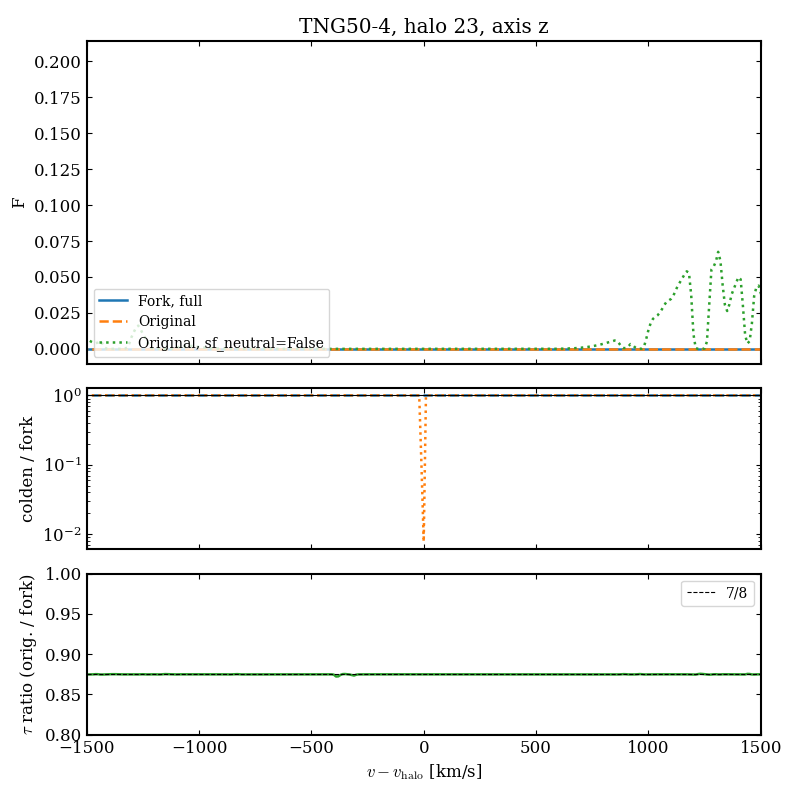

In [ ]:
# ==============================================================================
# CELL 5: FULL-MODE COMPARISON
# ==============================================================================
V_WINDOW = 1500.0                              # km/s shown around the halo
ref = "fork_full"
good = tau[ref] > 1e-6                         # skip pixels with no absorption

fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True,
                       gridspec_kw=dict(height_ratios=[2, 1, 1]))

# (a) flux of the three full-mode configs
for name, ls in [("fork_full", "-"), ("upstream", "--"), ("upstream_sf0", ":")]:
    ax[0].plot(v, flux[name], ls=ls, lw=1.8, label=CONFIGS[name][3])
ax[0].set_ylabel("F")
ax[0].legend(fontsize=10, loc="lower left")

# (b) colden ratio: 1 for the original; <1 where sf_neutral=False drops the
#     self-shielded HI of star-forming gas
for name, ls in [("upstream", "--"), ("upstream_sf0", ":")]:
    r = np.where(good, colden[name] / np.maximum(colden[ref], 1e-30), np.nan)
    ax[1].semilogy(v, r, ls=ls, lw=1.8, label=CONFIGS[name][3])
ax[1].axhline(1, color="k", lw=0.8)
ax[1].set_ylabel("colden / fork")

# (c) tau ratio with the same neutral fraction: only the 7/8 bug is left
r = np.where(good, tau["upstream"] / np.maximum(tau[ref], 1e-30), np.nan)
ax[2].plot(v, r, color="C2", lw=1.8)
ax[2].axhline(7 / 8, color="k", ls="--", lw=0.8, label="7/8")
ax[2].set_ylim(0.8, 1.0)
ax[2].set_ylabel(r"$\tau$ ratio (orig. / fork)")
ax[2].set_xlabel(r"$v - v_{\rm halo}$ [km/s]")
ax[2].legend(fontsize=10)

ax[0].set_xlim(-V_WINDOW, V_WINDOW)
ax[0].set_title(f"{SIM_NAME}, halo {HALO_ID}, axis {'xyz'[AXIS - 1]}")
fig.tight_layout()

# Numbers behind the plot (whole skewer, not only the window)
print(f"log N_HI total  fork: {np.log10(colden[ref].sum()):.3f}  "
      f"original: {np.log10(colden['upstream'].sum()):.3f}  "
      f"original sf0: {np.log10(colden['upstream_sf0'].sum()):.3f}")
print(f"max |colden original / fork - 1| = {np.nanmax(np.abs(colden['upstream'][good] / colden[ref][good] - 1)):.2e}")
print(f"median tau original / fork       = {np.median(tau['upstream'][good] / tau[ref][good]):.4f}  (7/8 = 0.875)")

## 4. HCD + Forest = full (fork)
tau is additive over cells, so `tau_HCD + tau_Forest = tau_full`, i.e.
`F_HCD * F_Forest = F_full`.

max |F_HCD F_Forest - F_full|          = 1.18e-37
max |tau_HCD + tau_Forest - tau_full| / max tau_full = 2.05e-13
log N_HI  HCD: 23.017   Forest: 15.794   full: 23.017


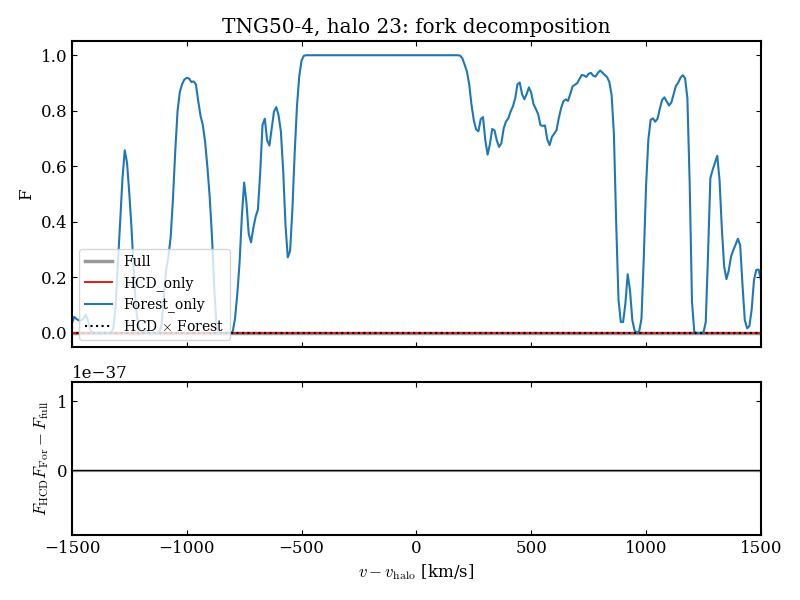

In [ ]:
# ==============================================================================
# CELL 6: DECOMPOSITION CHECK
# ==============================================================================
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                       gridspec_kw=dict(height_ratios=[2, 1]))

# (a) the two channels, the full spectrum and their product
ax[0].plot(v, flux["fork_full"], color="k", lw=2.5, alpha=0.4, label="Full")
ax[0].plot(v, flux["fork_HCD"], color="C3", lw=1.5, label="HCD_only")
ax[0].plot(v, flux["fork_Forest"], color="C0", lw=1.5, label="Forest_only")
ax[0].plot(v, flux["fork_HCD"] * flux["fork_Forest"], color="k", ls=":", lw=1.5,
           label=r"HCD $\times$ Forest")
ax[0].set_ylabel("F")
ax[0].legend(fontsize=10, loc="lower left")

# (b) residual of the product against the full spectrum
resid = flux["fork_HCD"] * flux["fork_Forest"] - flux["fork_full"]
ax[1].plot(v, resid, color="k", lw=1.2)
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set_ylabel(r"$F_{\rm HCD}F_{\rm For} - F_{\rm full}$")
ax[1].set_xlabel(r"$v - v_{\rm halo}$ [km/s]")

ax[0].set_xlim(-V_WINDOW, V_WINDOW)
ax[0].set_title(f"{SIM_NAME}, halo {HALO_ID}: fork decomposition")
fig.tight_layout()

print(f"max |F_HCD F_Forest - F_full|          = {np.abs(resid).max():.2e}")
print(f"max |tau_HCD + tau_Forest - tau_full| / max tau_full = "
      f"{np.abs(tau['fork_HCD'] + tau['fork_Forest'] - tau['fork_full']).max() / tau['fork_full'].max():.2e}")
print(f"log N_HI  HCD: {np.log10(colden['fork_HCD'].sum()):.3f}   "
      f"Forest: {np.log10(colden['fork_Forest'].sum()):.3f}   "
      f"full: {np.log10(colden['fork_full'].sum()):.3f}")

## 5. Timing
`init` = `Spectra(...)`, `tau` = `get_tau`, `colden` = `get_col_density`.
In the filtered modes the fork caches the particles read (and the HCD mask) during
`get_tau`, so `get_col_density` skips the disk. Most of the speed-up of
`HCD_only`/`Forest_only` is this cache, not the filter itself.

,init,tau,colden,total,relative
config,,,,,
upstream,0.0,0.52,0.43,0.95,1.00
upstream_sf0,0.0,0.51,0.40,0.91,0.96
fork_full,0.0,0.48,0.35,0.83,0.88
fork_HCD,0.0,0.47,0.00,0.47,0.50
fork_Forest,0.0,0.48,0.00,0.49,0.51


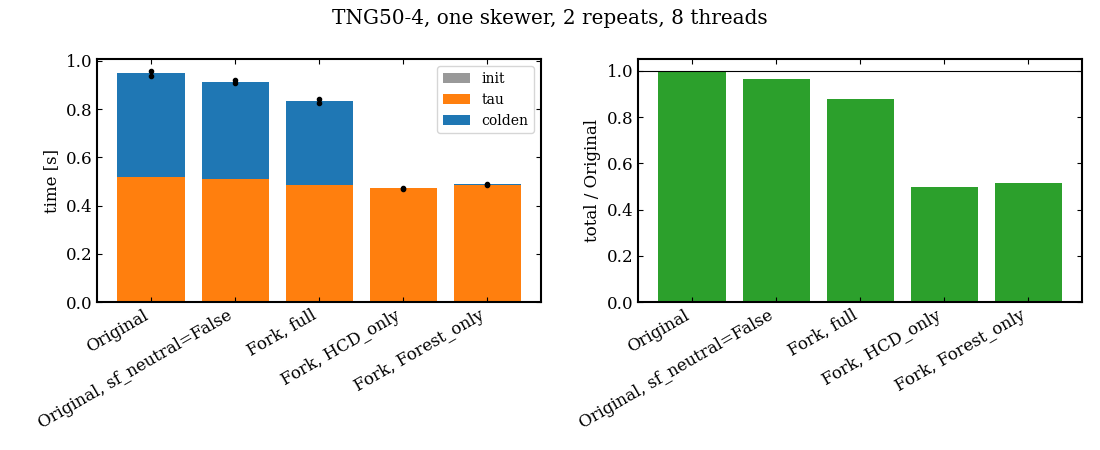

In [ ]:
# ==============================================================================
# CELL 7: TIMING COMPARISON
# ==============================================================================
stages = ["init", "tau", "colden"]
mean_t = timings.groupby("config", sort=False)[stages + ["total"]].mean()
labels = [CONFIGS[n][3] for n in mean_t.index]
x = np.arange(len(mean_t))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# (a) stacked mean time per stage
bottom = np.zeros(len(mean_t))
for stage, color in zip(stages, ["0.6", "C1", "C0"]):
    ax[0].bar(x, mean_t[stage], bottom=bottom, color=color, label=stage)
    bottom += mean_t[stage].values
# every repeat on top, to see the scatter (and the cold-cache first run)
for i, name in enumerate(mean_t.index):
    t = timings.loc[timings.config == name, "total"]
    ax[0].plot(np.full(len(t), i), t, "k.", ms=6)
ax[0].set_xticks(x, labels, rotation=30, ha="right")
ax[0].set_ylabel("time [s]")
ax[0].legend(fontsize=10)

# (b) total time relative to the original
t_ref = mean_t.loc["upstream", "total"]
ax[1].bar(x, mean_t["total"] / t_ref, color="C2")
ax[1].axhline(1, color="k", lw=0.8)
ax[1].set_xticks(x, labels, rotation=30, ha="right")
ax[1].set_ylabel("total / Original")

fig.suptitle(f"{SIM_NAME}, one skewer, {N_REPEAT} repeats, {N_THREADS} threads")
fig.tight_layout()

mean_t.assign(relative=mean_t["total"] / t_ref).round(2)